In [1]:
from pyprojroot import here
PROJECT_ROOT = here()
DATASET_DIR = PROJECT_ROOT/"Dataset"
MODEL_DIR = PROJECT_ROOT/"models"
IR_DIR = PROJECT_ROOT/"Pz and Sz"
FIG_DIR = PROJECT_ROOT / "figs" / "coherence"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(PROJECT_ROOT)
print(DATASET_DIR)
print(MODEL_DIR)
print(FIG_DIR)

/home/kobarin/Projects/Anc/GFANC-custom
/home/kobarin/Projects/Anc/GFANC-custom/Dataset
/home/kobarin/Projects/Anc/GFANC-custom/models
/home/kobarin/Projects/Anc/GFANC-custom/figs/coherence


In [2]:

import matplotlib.pyplot as plt
import numpy as np
import torch

from gfanc.common.loading_real_wave_noise import loading_real_wave_noise
from gfanc.common.Reading_path_test import loading_paths_from_MAT
from gfanc.data.Disturbance_generation import Disturbance_generation_from_real_noise
from gfanc.fxlms.FxLMS_algorithm_v2 import FxLMS, train_fxlms_algorithm, Noisy_FxLMS, train_fxlms_algorithm_for_noisy_ref
from gfanc.gfanc.Control_filter_selection_pre_now import Control_filter_selection_pre_now
from gfanc.gfanc.Fixed_filter_noise_cancellation_subfilters import Fixed_filter_controller, My_Fixed_filter_controller

print(torch.cuda.is_available())

False


In [3]:
# Loading real noises
mdict = {}
fs = 16000
StepSize = 0.0001
sound_name = 'Helicopter'
waveform, resample_rate = loading_real_wave_noise(folde_name=PROJECT_ROOT/'Real Noise Examples/', sound_name=sound_name+'.wav')
waveform = waveform[0].unsqueeze(0)

In [4]:

# Loading path
subfolder = "Dongyuan"
Pri_path, Secon_path = loading_paths_from_MAT(folder=IR_DIR, subfolder=subfolder, Pri_path_file_name='Primary_path.mat', Sec_path_file_name='Secondary_path.mat')
Dis, Fx, Re = Disturbance_generation_from_real_noise(fs=fs, Repet=0, wave_form=waveform, Pri_path=Pri_path, Sec_path=Secon_path)
# Dis: disturbance (cotrolled noise)， Fx: fixed-x signal, Re: repeated waveform (primary_noise) Repetition=Repet+1
import matplotlib as mpl

mpl.rcParams['agg.path.chunksize'] = 10000

In [5]:
def additional_noise(signal, snr_db):
    signal_power = signal.square().mean()
    additional_noise = torch.randn_like(signal, dtype=signal_power.dtype, device=signal_power.device)
    snr = 10 ** (snr_db / 10)
    noise_power = signal_power / snr
    return signal + noise_power.sqrt() * additional_noise

In [13]:
snrs = [np.inf, 20, 10, 5, 2.5, 1, 0, -1]
# GFANC: combining previous and present frame to predict the next
ErrorFixeds = {}
MODEL_PTH = MODEL_DIR/"M6_res_Synthetic.pth"
path_mat = MODEL_DIR/'Pretrained_Sub_Control_filters.mat'
for snr in snrs:
    if snr == np.inf:
        Ref = Re
    else:
        Ref = additional_noise(Re, snr)
    Filter_vector = Control_filter_selection_pre_now(fs=16000, MODEL_PTH=MODEL_PTH, path_mat=path_mat, Primary_noise=Ref.unsqueeze(0), threshold=0.5)

    Fixed_Cancellation = My_Fixed_filter_controller(Filter_vector=Filter_vector, fs=16000, Secondary_path=torch.tensor(Secon_path, dtype=torch.float32))
    ErrorFixed = Fixed_Cancellation.noise_cancellation(Dis=Dis, Ref=Ref)
    ErrorFixeds[snr] = 10*torch.log10(ErrorFixed.square().mean()/Dis.square().mean())
print(ErrorFixeds)

The primary nosie has 10 seconds !!!
1 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
2 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
3 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
4 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
5 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
6 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
7 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
8 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
9 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
10 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
The primary nosie has 10 seconds !!!
1 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
2 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
3 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
4 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
5 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
6 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
7 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
8 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
9 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
10 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
The primary nosie has 10 seconds !!!
1 [1 1 1 1 0 0 0 0 0 0 1 0 0 0 0]
2 [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
3 [1 1 1 1 0 0 0 0 0 0 1 0 0 0 0]
4 [1 1 1 1 0 0 0 0 0 0 1 1 0 0 0]
5 [1 1 1 1 0 0 0 0 0 0 1 1 0 0 0]
6 [1 1 1 1 0 0 0 0 0 0 1 0 0 0 0]
7 [

In [7]:
# FxLMS
snrs = [np.inf, 20, 10, 5, 2.5, 1, 0, -1]
ErrorFxLMSs = {}
StepSizes = [ StepSize * 10 ** i for i in range(2)]
for stepsize in StepSizes:
    ErrorTemp = {}
    for snr in snrs:
        if snr == np.inf:
            Ref = Re
        else:
            Ref = additional_noise(Re, snr)
        controller = Noisy_FxLMS(Len=1024) # 1024 is the same size of coeffient vector of fixed-filter
        ErrorFxLMS = train_fxlms_algorithm_for_noisy_ref(Model=controller, Ref=Ref, Disturbance=Dis, Secondary_path=torch.tensor(Secon_path, dtype=torch.float32), filter_len=1024, Stepsize=stepsize) # torch.Size([320000])
        ErrorTemp[snr] = 10*torch.log10(torch.tensor(ErrorFxLMS).square().sum()/Dis.square().sum())
    ErrorFxLMSs[stepsize] = ErrorTemp
print(ErrorFxLMSs)


[========================================================================] 100%
[========================================================================] 100%
[========================================================================] 100%
[========================================================================] 100%
[========================================================================] 100%
[========================================================================] 100%
[========================================================================] 100%
[========================================================================] 100%
[========================================================================] 100%
[========================================================================] 100%
[========================================================================] 100%
[========================================================================] 100%
[=======================================

{0.0001: {inf: tensor(-5.0694), 20: tensor(-5.0322), 10: tensor(-4.7201), 5: tensor(-4.1391), 2.5: tensor(-3.6623), 1: tensor(-3.3651), 0: tensor(-3.1570), -1: tensor(-2.7911)}, 0.001: {inf: tensor(-10.9335), 20: tensor(-10.3767), 10: tensor(-7.7660), 5: tensor(-5.6907), 2.5: tensor(-4.5357), 1: tensor(-3.8817), 0: tensor(-3.2947), -1: tensor(-2.9189)}}


[========================================================================] 100%


In [8]:
# # FxLMS
# snrs = [20, 10, 5, 2.5, 1, 0, -1]
# StepSizes = StepSize * 10 ** 3
# stepsize=StepSizes
# ErrorTemp = {}
# for snr in snrs:
#     _, Noisy_Fx, _ = Disturbance_generation_from_real_noise(fs=fs, Repet=0, wave_form=waveform, Pri_path=Pri_path, Sec_path=Secon_path)
#     Noisy_Fx = additional_noise(Noisy_Fx, snr)
#     controller = FxLMS(Len=1024) # 1024 is the same size of coeffient vector of fixed-filter
#     ErrorFxLMS = train_fxlms_algorithm_for_noisy_ref(Model=controller, Ref=Noisy_Fx, Disturbance=Dis, Stepsize=stepsize) # torch.Size([320000])
#     ErrorTemp[snr] = 10*torch.log10(torch.tensor(ErrorFxLMS).square().sum()/Dis.square().sum())

# print(ErrorTemp)


In [9]:
print(ErrorFixeds, ErrorFxLMSs)

{inf: tensor(3.4932), 20: tensor(3.5470), 10: tensor(4.3775), 5: tensor(7.7483), 2.5: tensor(9.7683), 1: tensor(10.9135), 0: tensor(11.7624), -1: tensor(12.8184)} {0.0001: {inf: tensor(-5.0694), 20: tensor(-5.0322), 10: tensor(-4.7201), 5: tensor(-4.1391), 2.5: tensor(-3.6623), 1: tensor(-3.3651), 0: tensor(-3.1570), -1: tensor(-2.7911)}, 0.001: {inf: tensor(-10.9335), 20: tensor(-10.3767), 10: tensor(-7.7660), 5: tensor(-5.6907), 2.5: tensor(-4.5357), 1: tensor(-3.8817), 0: tensor(-3.2947), -1: tensor(-2.9189)}}


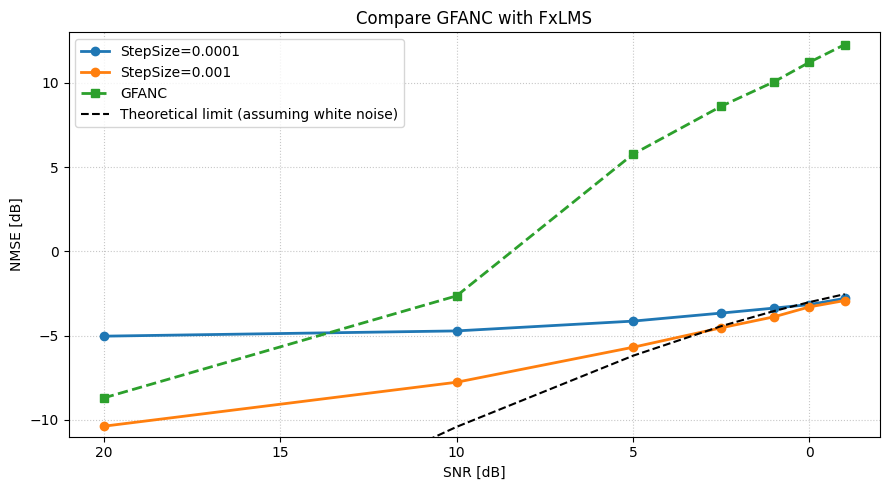

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
snrs = np.array(snrs)
for param, values in ErrorFxLMSs.items():
    x = snrs
    y = [ float(values[snr]) for snr in snrs ]

    ax.plot(
        x, y,
        marker="o",
        linewidth=2,
        label=f"StepSize={param}",
    )

# GFANC
x = snrs
y = [ float(ErrorFixeds[snr]) for snr in snrs ]

ax.plot(
    x, y,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="GFANC",
)

ax.plot(snrs, -10 * np.log10(1 + 10 ** (snrs / 10)), 'k--', label='Theoretical limit (assuming white noise)')

ax.set_xlabel("SNR [dB]")
ax.set_ylabel("NMSE [dB]")
ax.set_ylim(-11, 13)
ax.set_xlim(-2, 21)
ax.invert_xaxis() 
ax.set_title("Compare GFANC with FxLMS")

ax.grid(True, linestyle=":", alpha=0.7)
ax.legend()
fig.tight_layout()
plt.show()